# Quality control on S, C and X band: noise, clutter, interference, speckle

**radar-wow stage 2.** Algorithms (all in `radarwow.qc`, same interface):

| sub-component | algorithm | paper |
|---|---|---|
| noise | `SignalMask` | SNR / SQI thresholds, else the measured noise floor (`radarwow.core.noise`) |
| ground clutter | `Hubbert2009CMD` | Hubbert, Dixon & Ellis 2009, JTECH, doi:10.1175/2009JTECHA1160.1 (no CPA: archived moments have no I/Q) |
| non-meteorological echo | `Vulpiani2012QualityMap` | Vulpiani, Montopoli et al. 2012, JAMC, doi:10.1175/JAMC-D-10-05024.1 |
| RLAN / sun / emitter spikes | `InterferenceSpikes` | after Saltikoff et al. 2016, BAMS, doi:10.1175/BAMS-D-15-00048.1 |
| speckle | `Despeckle` | connected-component size filter |
| birds / insects | `MistNet` | Lin et al. 2019, MEE, doi:10.1111/2041-210X.13280 (stub: needs the pretrained model) |

Step 1 scores each on synthetic sweeps with known truth; step 2 runs the chain on free real data per band.

In [1]:
# Colab: uncomment to install
!pip install -q "git+https://github.com/manmeet3591/radarwow-core" "git+https://github.com/manmeet3591/radarwow-qc"

zsh:1: command not found: pip


In [2]:
import time
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from radarwow.core import diagnose, load_sample
from radarwow.core.plotting import ppi
from radarwow.core.testing import synthetic_sweep
from radarwow.qc import Despeckle, Hubbert2009CMD, InterferenceSpikes, SignalMask, Vulpiani2012QualityMap

FIG = "../docs/figures"

## 1. Synthetic sweeps with known clutter and an interference spike

| band | algorithm | POD (clutter) | false-alarm rate (weather gates) |
|---|---|---|---|
| S | Hubbert 2009 CMD | 0.93 | 0.000 |
| S | Vulpiani 2012 quality map | 1.00 | 0.060 |
| C | Hubbert 2009 CMD | 0.93 | 0.000 |
| C | Vulpiani 2012 quality map | 1.00 | 0.060 |
| X | Hubbert 2009 CMD | 0.93 | 0.000 |
| X | Vulpiani 2012 quality map | 1.00 | 0.060 |

Interference rays found: [np.int64(200)] (truth: [200])

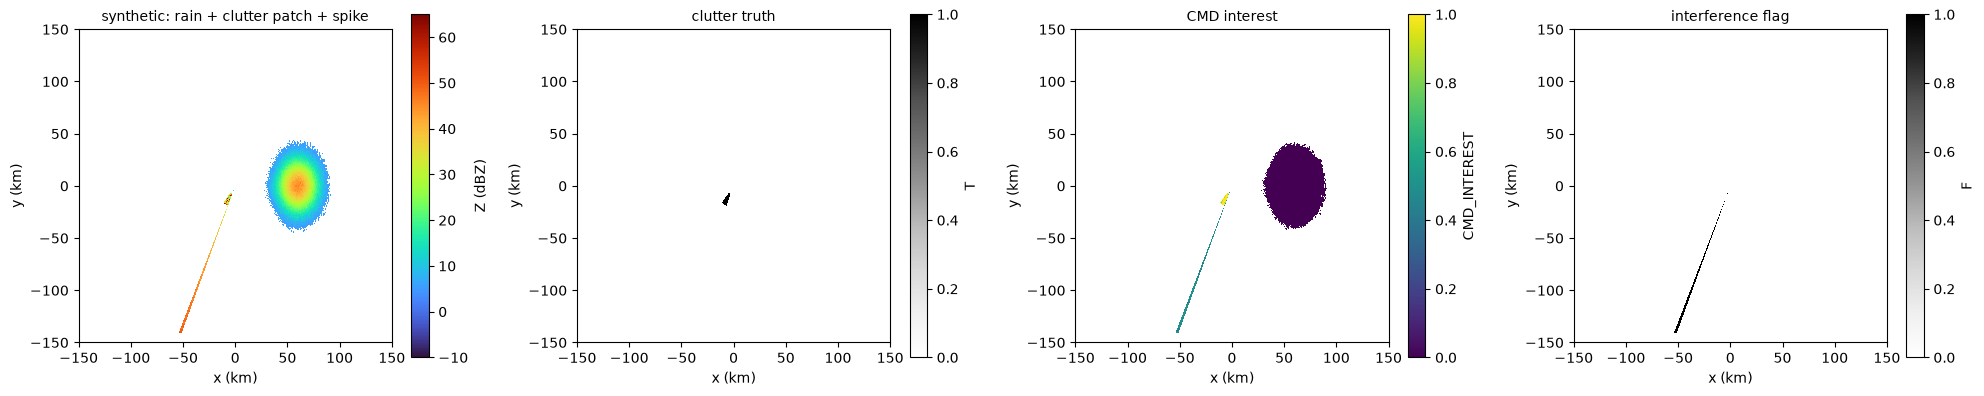

In [3]:
def scores(flag, truth, valid):
    return (flag & truth).sum() / truth.sum(), (flag & ~truth & valid).sum() / (~truth & valid).sum()


rows = ["| band | algorithm | POD (clutter) | false-alarm rate (weather gates) |", "|---|---|---|---|"]
for band in ("S", "C", "X"):
    for seed in range(1):
        ds = synthetic_sweep(seed=10 + seed, spike_az=200)
        valid = np.isfinite(ds["DBZH"].values)
        truth = ds["CLUTTER_TRUTH"].values
        for label, flag in (("Hubbert 2009 CMD", Hubbert2009CMD()(ds, band=band)["CMD_FLAG"]),
                            ("Vulpiani 2012 quality map", Vulpiani2012QualityMap()(ds, band=band)["QC_FLAG"])):
            pod, fa = scores(flag.values.astype(bool), truth, valid)
            rows.append(f"| {band} | {label} | {pod:.2f} | {fa:.3f} |")
display(Markdown("\n".join(rows)))
spike = InterferenceSpikes()(ds, band="C")
display(Markdown(f"Interference rays found: {list(np.flatnonzero(spike['INTERFERENCE_RAY'].values))} (truth: [200])"))

cmd = Hubbert2009CMD()(ds, band="C")
fig, ax = plt.subplots(1, 4, figsize=(20, 4.6))
ppi(ds, "DBZH", ax=ax[0], max_km=150, title="synthetic: rain + clutter patch + spike")
ppi(ds.assign(T=ds["CLUTTER_TRUTH"].astype(float)), "T", ax=ax[1], max_km=150, title="clutter truth", cmap="Greys", vmin=0, vmax=1)
ppi(cmd, "CMD_INTEREST", ax=ax[2], max_km=150, title="CMD interest", cmap="viridis", vmin=0, vmax=1)
ppi(spike.assign(F=spike["INTERFERENCE_FLAG"].astype(float)), "F", ax=ax[3], max_km=150, title="interference flag", cmap="Greys", vmin=0, vmax=1)
fig.tight_layout()
fig.savefig(f"{FIG}/01_synthetic.png", dpi=100)
plt.show()

## 2. Real data: one chain, three radars
Chain: `SignalMask → InterferenceSpikes → Hubbert2009CMD → Vulpiani2012QualityMap → Despeckle`.
Each algorithm only flags; the final mask is their union, so we can show what each step removed.

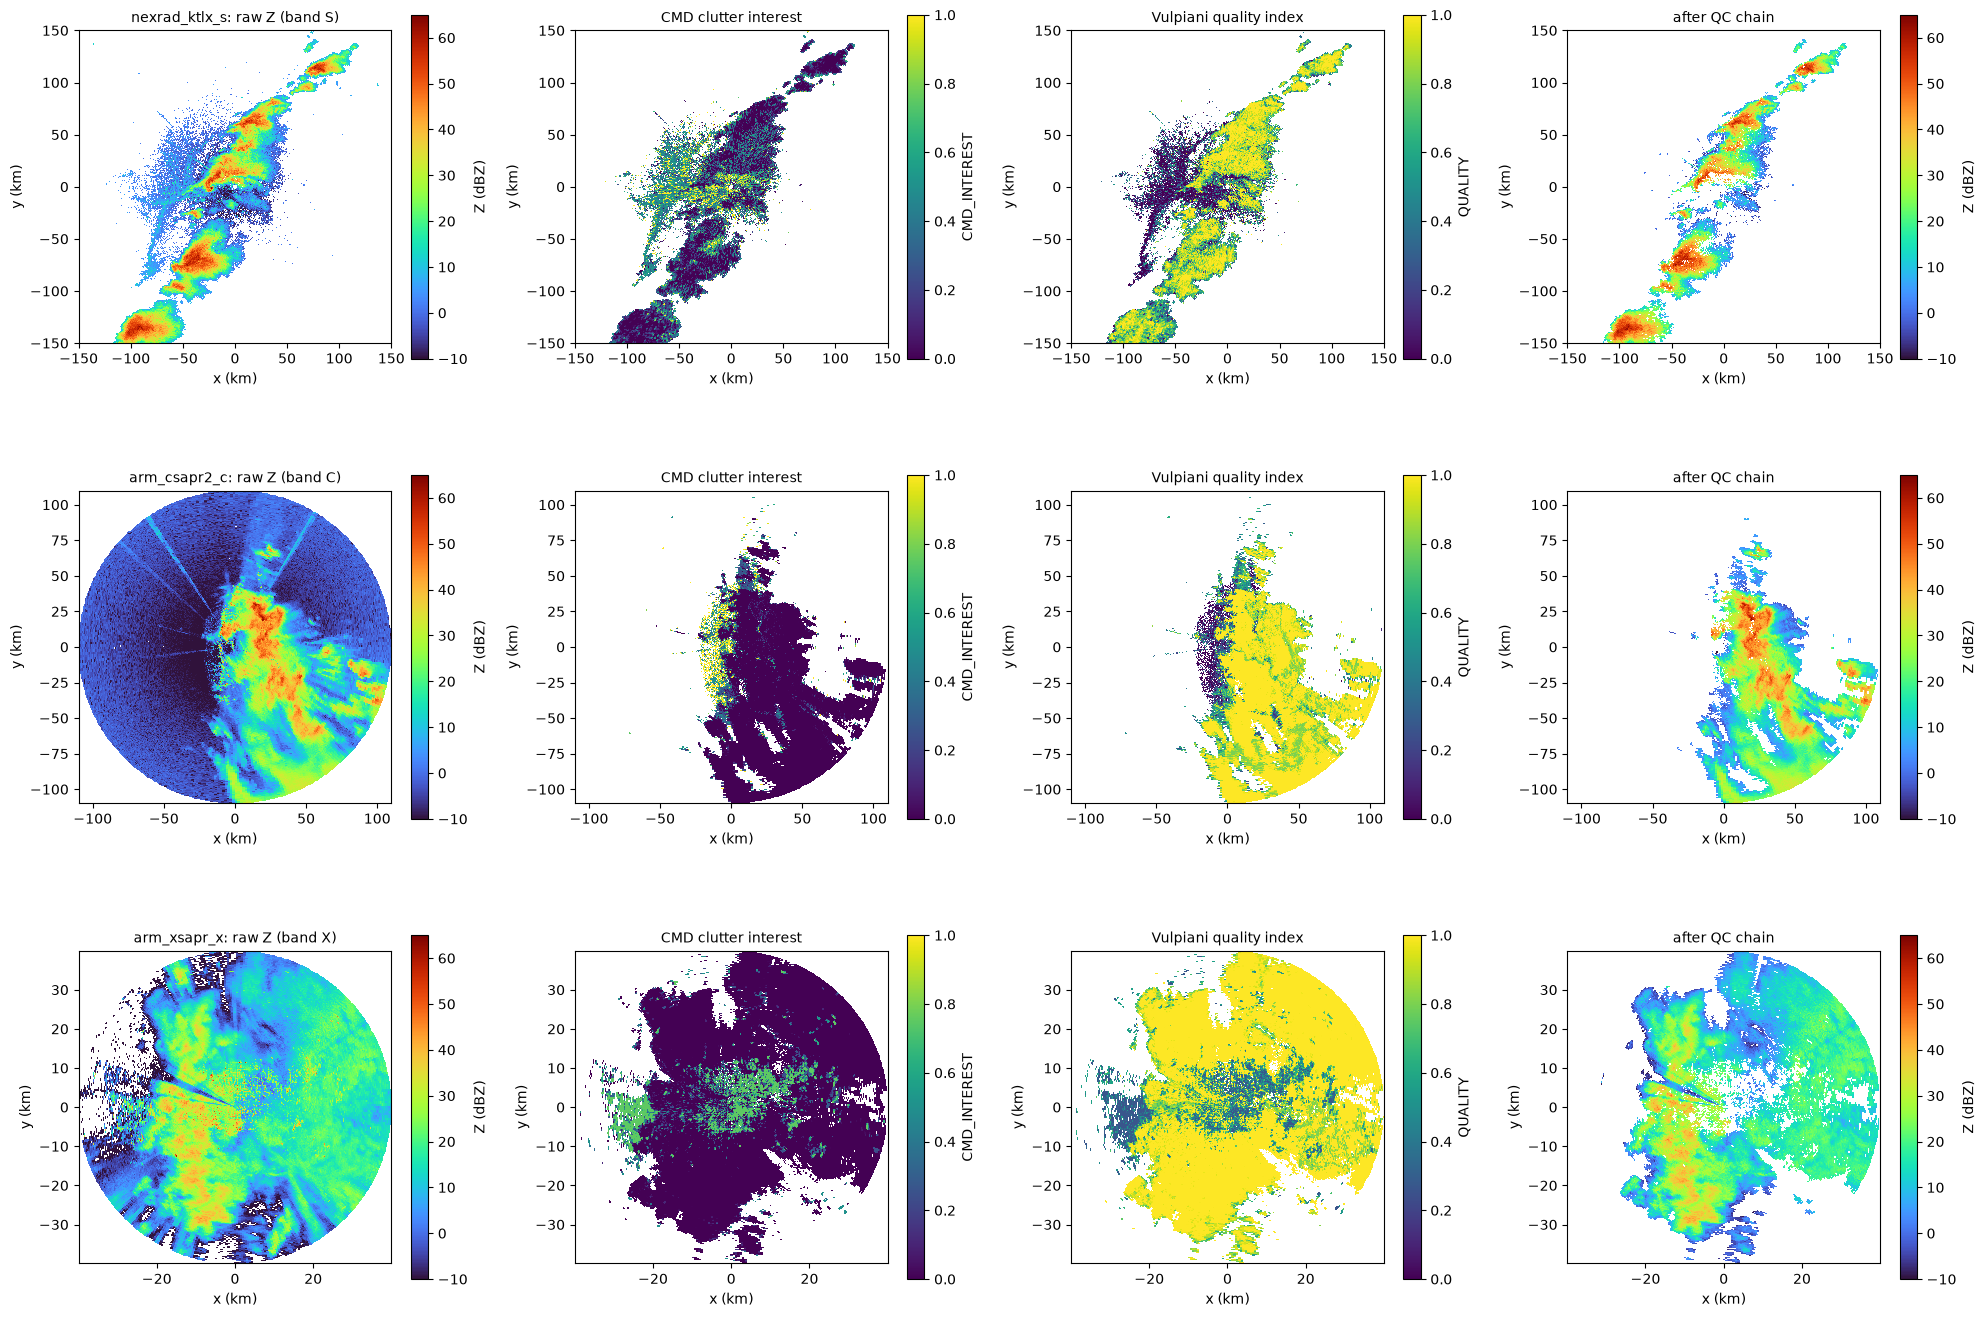

| sample | band | signal gates | interference rays | CMD clutter | quality-map reject | speckle | kept | runtime (s) |
|---|---|---|---|---|---|---|---|---|
| nexrad_ktlx_s | S | 100% of finite | 0 | 22.0% | 42.5% | 2.7% | 50% | 0.2 |
| arm_csapr2_c | C | 45% of finite | 0 | 13.5% | 23.0% | 0.8% | 76% | 0.1 |
| arm_xsapr_x | X | 83% of finite | 2 | 16.3% | 16.4% | 1.0% | 77% | 0.1 |

In [4]:
samples = {"S": "nexrad_ktlx_s", "C": "arm_csapr2_c", "X": "arm_xsapr_x"}
rows = ["| sample | band | signal gates | interference rays | CMD clutter | quality-map reject | speckle | kept | runtime (s) |",
        "|---|---|---|---|---|---|---|---|---|"]
fig, axes = plt.subplots(3, 4, figsize=(20, 14))
for row, (band, name) in enumerate(samples.items()):
    dt = load_sample(name)
    rep = diagnose(dt)
    ds = dt[rep.sweep].to_dataset()
    t = time.time()
    sig = SignalMask(mask_output=False)(ds, band=band)["SIGNAL"].values.astype(bool)
    s1 = ds.copy()
    s1["DBZH"] = ds["DBZH"].where(sig)
    intf = InterferenceSpikes()(s1, band=band)
    cmd = Hubbert2009CMD()(s1, band=band)
    qm = Vulpiani2012QualityMap()(s1, band=band) if all(m in ds for m in ("RHOHV", "PHIDP")) else None
    bad = intf["INTERFERENCE_FLAG"].values.astype(bool) | cmd["CMD_FLAG"].values.astype(bool)
    if qm is not None:
        bad |= qm["QC_FLAG"].values.astype(bool)
    s2 = s1.copy()
    s2["DBZH"] = s1["DBZH"].where(~bad)
    sp = Despeckle(mask_output=False)(s2, band=band)["SPECKLE_FLAG"].values.astype(bool)
    final = s2["DBZH"].where(~sp)
    dt_run = time.time() - t
    n = np.isfinite(ds["DBZH"].values).sum()

    def pct(m):
        return f"{100 * (m & sig).sum() / max(sig.sum(), 1):.1f}%"

    rows.append(f"| {name} | {band} | {100 * sig.sum() / n:.0f}% of finite | {int(intf['INTERFERENCE_RAY'].sum())} | "
                f"{pct(cmd['CMD_FLAG'].values.astype(bool))} | {pct(qm['QC_FLAG'].values.astype(bool)) if qm is not None else '-'} | "
                f"{pct(sp)} | {100 * np.isfinite(final.values).sum() / max(sig.sum(), 1):.0f}% | {dt_run:.1f} |")
    km = min(150.0, float(ds["range"].values[-1]) / 1e3)
    ppi(ds, "DBZH", ax=axes[row, 0], max_km=km, title=f"{name}: raw Z (band {band})")
    ppi(cmd, "CMD_INTEREST", ax=axes[row, 1], max_km=km, title="CMD clutter interest", cmap="viridis", vmin=0, vmax=1)
    if qm is not None:
        ppi(qm, "QUALITY", ax=axes[row, 2], max_km=km, title="Vulpiani quality index", cmap="viridis", vmin=0, vmax=1)
    else:
        axes[row, 2].set_axis_off()
    ppi(ds.assign(DBZH=final), "DBZH", ax=axes[row, 3], max_km=km, title="after QC chain")
fig.tight_layout()
fig.savefig(f"{FIG}/02_real_qc_chain.png", dpi=95)
plt.show()
display(Markdown("\n".join(rows)))

## Takeaways
- Real archives differ before QC even starts: NEXRAD stores "below threshold" as −33 dBZ, the ARM
  files store noise (so `SignalMask` matters most there), and only some sources have SNR/SQI.
- On KTLX the quality map rejects 42 % of signal gates: mostly the low-Z, low-rhoHV clear-air /
  biological echo around the radar, which is correct, but also some stratiform edges with low
  rhoHV in the far south-west cell. Tuning its rhoHV ramp per band is the next step.
- Thresholds in CMD and the quality map are our documented assumptions where the papers give
  none; they are per-band/per-radar parameters, not constants.
- Biological echo (MistNet) needs the pretrained network and velocity/spectrum width at all
  five MistNet elevations; it is a stub until we wire in the weights.